# Modelagem: probabilidade de inadimplência

Este notebook parte da base construída em `01_EDA_and_Feature_engineering.ipynb` e entrega o modelo final e o arquivo `submissao_case.csv`.

| Seção | O que faz |
|---|---|
| 1. Dados | Carrega a base de modelagem e define features e targets |
| 2. Split temporal | Treino e teste por data do pedido |
| 3. Modelos candidatos | Regressão logística (WoE), HistGradientBoosting e XGBoost |
| 4. Com qual target treinar? | Limiar de atraso menor para ter mais maus no treino; escolha do modelo e tuning dos hiperparâmetros e do limiar, só com dados do treino |
| 5. Teste fora do tempo | Confirmação no EVER30MOB12, no default de Basileia e em Cash loans |
| 6. Calibração | Ajuste do nível da PD à safra mais recente, com um nível por produto |
| 7. Interpretação | Coeficientes da logística; importância e curvas de resposta do modelo final |
| 8. Segmentos | O modelo funciona igual para todos os grupos? |
| 9. Resumo e trabalhos futuros | Decisões, limitações e o que falta |

Todo o código de split, modelos e avaliação está em `modelagem.py`; aqui só instanciamos as classes.

**Lembretes da EDA:**
- O target é **EVER30MOB12**: 30+ dias de atraso nos 12 primeiros meses. O **EVER90MOB12** (default de Basileia) é o benchmark.
- A taxa de maus cai muito nas safras recentes, e a submissão é dominada por Cash loans.
- As features que descrevem o tamanho e o prazo do pedido mudam muito entre o treino e a submissão (PSI, seção 6.3 da EDA).

In [1]:
import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # evita aviso do joblib no Windows
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from modelagem import (
    SEED, CalibradorPlatt, ModeloCalibrado, ModeloHistGradient, ModeloLogistico, ModeloXGBoost,
    SplitTemporal, TuningXGBoost, avaliar, comparar_calibracao_cv, dependencia_parcial, gini_em_cortes_internos, ic_gini,
    importancia_permutacao, plot_calibracao, plot_roc_ks, tabela_faixas,
)
from target_engineering import TARGET_PRINCIPAL, TargetEngineering

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
AZUL, LARANJA, AQUA, ROXO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
PASTA_SAIDA = Path("outputs")
PASTA_SAIDA.mkdir(exist_ok=True)

## 1. Dados

- `base_modelagem.parquet` traz **todos** os contratos aprovados. Os contratos imaturos (target nulo) ficam fora do treino dos três modelos. Aproveitá-los é um trabalho futuro (seção 10).
- `base_score.parquet` são os pedidos a pontuar.

**Features.** São as mesmas colunas da base de score, exceto:
- `sexo`, que fica de fora por **equidade**. Ele tinha IV ~0, e um modelo de crédito não deve usar sexo para decidir. Mesmo excluído, verificamos na seção 8 se o modelo trata os dois grupos de forma parecida.
- **oito features de tamanho e prazo do pedido:** `valor_credito`, `valor_bem`, `valor_parcela`, `prazo_estimado_meses`, `parcela_sobre_credito`, `credito_sobre_bem`, `credito_sobre_renda` e `parcela_sobre_renda`.


**Targets com limiar menor.** Além do EVER30MOB12, calculamos o mesmo target com cada limiar de 5 a 29 dias de atraso, com a mesma classe `TargetEngineering` da EDA e a mesma data de observação por cliente (seção 5.2 da EDA). Eles são candidatos a **target de treino** (seção 4), porque têm mais maus para o modelo aprender. A avaliação, a calibração e a PD entregue continuam sendo no EVER30MOB12.

In [2]:
TARGET = TARGET_PRINCIPAL          # target_ever30mob12
TARGET_BASILEIA = "target_ever90mob12"

aprovados = pd.read_parquet("data/processed/base_modelagem.parquet")
base_score = pd.read_parquet("data/processed/base_score.parquet")
base = aprovados[aprovados[TARGET].notna()].reset_index(drop=True)

# Tamanho e prazo do pedido: ficam fora do modelo (motivos no texto acima; efeito medido na seção 9.1)
FEATURES_DO_PEDIDO = ["valor_credito", "valor_bem", "valor_parcela", "prazo_estimado_meses", "parcela_sobre_credito",
                      "credito_sobre_bem", "credito_sobre_renda", "parcela_sobre_renda"]
FEATURES_TODAS = [c for c in base_score.columns if c not in ("id_cliente", "data_referencia", "sexo")]
FEATURES = [c for c in FEATURES_TODAS if c not in FEATURES_DO_PEDIDO]
CATEGORICAS = [c for c in FEATURES if base_score[c].dtype == object]
assert set(FEATURES_DO_PEDIDO) <= set(FEATURES_TODAS) <= set(base.columns)

# Targets com limiar menor: candidatos a target de TREINO (seção 4). A avaliação é sempre no EVER30MOB12.
# Mesma data de observação por cliente da EDA: a data do pedido de cada cliente na submissão (seção 5.2 da EDA)
observacao_por_cliente = base_score.set_index("id_cliente")["data_referencia"]
te = TargetEngineering(pd.read_parquet("data/historico_emprestimos.parquet"), pd.read_parquet("data/historico_parcelas.parquet"),
                       observacao_por_cliente)
alvos = {}
for dias in range(5, 30):   # um target para cada limiar de 5 a 29 dias; o de 30 já está na base
    alvo = te.construir_target(dias_atraso=dias, meses=12)
    coluna = alvo.columns[-1]
    alvos[coluna] = base["id_contrato"].map(alvo.set_index("id_contrato")[coluna]).astype(int)
base = pd.concat([base, pd.DataFrame(alvos)], axis=1)

DIAS_COMPARACAO = (30, 20, 15, 10, 7, 5)   # limiares usados na comparação dos modelos (seção 4)
TARGETS_TREINO = [TuningXGBoost.coluna_target(dias) for dias in DIAS_COMPARACAO]
assert TARGETS_TREINO[0] == TARGET

print(f"Contratos rotulados: {len(base):,} | taxa {TARGET}: {base[TARGET].mean():.2%} | {TARGET_BASILEIA}: {base[TARGET_BASILEIA].mean():.2%}")
print(f"Contratos imaturos (fora do treino): {aprovados[TARGET].isna().sum():,}")
print(f"Features: {len(FEATURES)} ({len(FEATURES) - len(CATEGORICAS)} numéricas, {len(CATEGORICAS)} categóricas)")
display(pd.DataFrame({"maus": base[TARGETS_TREINO].sum().astype(int), "taxa_%": (base[TARGETS_TREINO].mean() * 100).round(2)}).rename_axis("target"))

Contratos rotulados: 89,532 | taxa target_ever30mob12: 2.17% | target_ever90mob12: 0.44%
Contratos imaturos (fora do treino): 26,650
Features: 42 (32 numéricas, 10 categóricas)


,maus,taxa_%
target,,
target_ever30mob12,1947,2.17
target_ever20mob12,4229,4.72
target_ever15mob12,5684,6.35
target_ever10mob12,8455,9.44
target_ever7mob12,11407,12.74
target_ever5mob12,14847,16.58


## 2. Split temporal

O modelo vai pontuar pedidos **futuros**, então a avaliação precisa imitar isso: treinar no passado e medir em safras posteriores. Um split aleatório misturaria 2017 com 2024 e superestimaria o desempenho.

| Período | Pedidos | Uso |
|---|---|---|
| **Treino** | até jun/2023 | Ajuste dos modelos |
| **Teste** | jul/2023 a fev/2024 | Avaliação final e calibração do nível da PD |

- **Só duas partes.** Não separamos um período de validação: ele tiraria do treino justamente as safras mais recentes, que são as mais parecidas com a submissão.

,de,ate,contratos,maus,taxa_maus_%
periodo,,,,,
treino,2017-02-04,2023-06-30,73086,1848,2.53
teste,2023-07-01,2024-02-24,16446,99,0.60


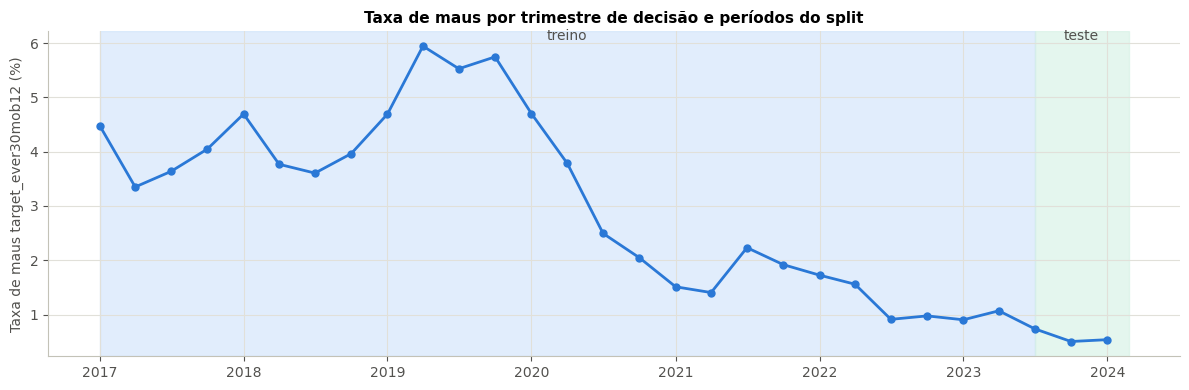

In [3]:
split = SplitTemporal(inicio_teste="2023-07-01")
treino, teste = split.separar(base)
display(split.resumo({"treino": treino, "teste": teste}, TARGET))

trimestral = base.groupby(base["data_referencia"].dt.to_period("Q").dt.to_timestamp())[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trimestral.index, trimestral["mean"] * 100, marker="o", markersize=5, linewidth=2, color=AZUL)
for inicio, fim, nome, cor in [(trimestral.index.min(), split.inicio_teste, "treino", "#cde2fb"),
                               (split.inicio_teste, base["data_referencia"].max(), "teste", "#d3f0e4")]:
    ax.axvspan(inicio, fim, color=cor, alpha=0.6, zorder=0)
    ax.text(inicio + (fim - inicio) / 2, trimestral["mean"].max() * 100 * 1.02, nome, ha="center", color="#52514e")
ax.set_ylabel(f"Taxa de maus {TARGET} (%)")
ax.set_title("Taxa de maus por trimestre de decisão e períodos do split")
plt.tight_layout()
plt.show()

- **O treino agora inclui as safras recentes.** São 73 mil contratos até jun/2023, com 1.848 maus. Os 12 meses mais recentes do treino (jul/2022 a jun/2023) já têm a inadimplência baixa dos últimos anos, parecida com a do teste.
- **A taxa de maus cai de 2,5% no treino para 0,60% no teste.** Isso tem duas consequências:
  - **Ordenação:** a AUC continua comparável entre períodos, porque mede ordem e não nível.
  - **Nível da PD:** um modelo treinado no passado **superestima** a PD dos pedidos recentes. A seção 6 corrige isso com calibração.
- **O teste tem só 99 maus.** As métricas dele têm incerteza grande. Por isso mostramos o intervalo de confiança e não lemos diferenças pequenas ao pé da letra.

## 3. Modelos candidatos

Três modelos, do mais simples ao mais complexo:

| Modelo | Como funciona | Interpretabilidade |
|---|---|---|
| **Regressão logística com WoE** | Cada feature vira o WoE da sua faixa: nulos e categorias raras viram faixas próprias, e outliers ficam limitados à última faixa. Features com IV < 0,02 saem | Total. É o padrão de mercado em concessão e vira um scorecard de pontos |
| **HistGradientBoosting** | Gradient boosting do scikit-learn. Agrupa cada feature em faixas (histograma) e cresce árvores pequenas em sequência, cada uma corrigindo o erro das anteriores. Usa categóricas e nulos diretamente | Parcial, via importância e curvas de resposta |
| **XGBoost** | Gradient boosting com a mesma ideia, mais regularização nas folhas e amostragem de linhas e colunas a cada árvore. Também usa categóricas e nulos diretamente | Parcial, via importância e curvas de resposta |


**Desbalanceamento.** Nenhum modelo usa peso de classe (`class_weight="balanced"`). Pesos não melhoram a ordenação de forma relevante e distorcem a PD, que precisa sair como probabilidade de verdade para a política de crédito.

**Métricas:**
- **AUC:** probabilidade de um mau aleatório ter score pior que um bom aleatório.
- **Gini:** `2·AUC − 1`, a forma usual em crédito.
- **KS:** a maior separação entre as distribuições acumuladas de bons e maus.
- **Brier:** qualidade da probabilidade (nível).

In [4]:
# Ponto de partida do XGBoost. O tuning da seção 4.1 parte destes valores.
PARAMS_XGBOOST = dict(n_estimators=400, max_depth=3, learning_rate=0.03, reg_lambda=5, min_child_weight=5,
                      subsample=0.8, colsample_bytree=0.8)

FABRICAS = {
    "Logística (WoE)": lambda: ModeloLogistico(n_faixas=8, iv_minimo=0.02, C=1.0),
    "HistGradientBoosting": lambda: ModeloHistGradient(
        CATEGORICAS, max_iter=300, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=200, l2_regularization=1.0),
    "XGBoost": lambda: ModeloXGBoost(CATEGORICAS, **PARAMS_XGBOOST),
}

## 4. Com qual target treinar? Mais maus com um limiar menor

**O problema.** O treino tem menos de 2 mil maus EVER30MOB12 em 73 mil contratos. É pouco para um modelo aprender, e é o que mais limita o desempenho.

**A ideia.** A EDA (seção 6.4) mostrou que um modelo treinado com EVER30 ordena melhor o default de Basileia (EVER90) do que um modelo treinado com o próprio EVER90, porque tem mais eventos para aprender. Aqui damos mais um passo na mesma direção: treinar com um limiar **menor que 30 dias**, que tem ainda mais maus, e medir se o modelo ordena melhor o **EVER30MOB12**.

- O **target de treino** é só o rótulo que o modelo usa para aprender.
- O **target do negócio não muda**: a avaliação, a calibração e a PD entregue são sempre no EVER30MOB12.
- O risco é o limiar ficar baixo demais: quem atrasa 5 dias pode ser só esquecido, e não um cliente de risco. Por isso testamos vários limiares.

**O experimento.** Para não usar o teste na escolha, o experimento fica **dentro do treino**, com dois cortes temporais (o mesmo desenho da seção 6.4 da EDA):

| Corte | Treina com pedidos até | Mede o Gini no EVER30MOB12 em |
|---|---|---|
| 1 | jun/2021 | jul/2021 a jun/2023 |
| 2 | jun/2022 | jul/2022 a jun/2023 |

Cada um dos três modelos é treinado com seis limiares (30, 20, 15, 10, 7 e 5 dias), com parâmetros fixos, e a tabela mostra o Gini médio dos dois cortes.

**O que este experimento decide:**
1. **Se a ideia funciona:** se um limiar menor melhora o Gini no EVER30MOB12 nos três modelos.
2. **O modelo:** começa-se pela logística, o mais simples. O melhor dos outros dois só a substitui se ganhar **pelo menos 2 pontos de Gini** no limiar de maior Gini médio. Abaixo disso, a simplicidade vale mais que o ganho.

O limiar exato não é escolhido aqui. Ele entra como hiperparâmetro no tuning do modelo escolhido (seção 4.1).

In [5]:
%%time
CORTES_INTERNOS = ["2021-07-01", "2022-07-01"]
resultado = gini_em_cortes_internos(FABRICAS, treino, FEATURES, TARGETS_TREINO, target_avaliacao=TARGET, cortes=CORTES_INTERNOS)
gini_interno = resultado.pivot_table(index="treinado_com", columns="modelo", values="Gini").loc[TARGETS_TREINO, list(FABRICAS)]
gini_interno["média dos modelos"] = gini_interno.mean(axis=1)
gini_interno.insert(0, "maus no treino", [int(treino[t].sum()) for t in TARGETS_TREINO])
print("Gini no EVER30MOB12, média dos dois cortes internos:")
display(gini_interno.round(4))
print("Por corte:")
display(resultado.pivot_table(index="treinado_com", columns=["corte", "modelo"], values="Gini").loc[TARGETS_TREINO].round(3))
print("Só Cash loans, média dos dois cortes internos:")
display(resultado.pivot_table(index="treinado_com", columns="modelo", values="Gini_cash").loc[TARGETS_TREINO, list(FABRICAS)].round(4))

TARGET_COMPARACAO = gini_interno["média dos modelos"].idxmax()
melhor = gini_interno.loc[TARGET_COMPARACAO, list(FABRICAS)].astype(float).idxmax()
ganho = gini_interno.loc[TARGET_COMPARACAO, melhor] - gini_interno.loc[TARGET_COMPARACAO, "Logística (WoE)"]
MODELO_FINAL = melhor if ganho >= 0.02 else "Logística (WoE)"
print(f"Limiar com o maior Gini médio: {TARGET_COMPARACAO}")
print(f"Melhor modelo com esse limiar: {melhor} ({ganho * 100:+.1f} pontos de Gini sobre a logística)")
print("Modelo escolhido:", MODELO_FINAL)

Gini no EVER30MOB12, média dos dois cortes internos:


modelo,maus no treino,Logística (WoE),HistGradientBoosting,XGBoost,média dos modelos
treinado_com,,,,,
target_ever30mob12,1848,0.2576,0.2856,0.3087,0.2840
target_ever20mob12,4026,0.2968,0.3040,0.3212,0.3073
target_ever15mob12,5400,0.2957,0.3300,0.3336,0.3198
target_ever10mob12,7870,0.3216,0.3488,0.3605,0.3436
target_ever7mob12,10382,0.2938,0.3641,0.3817,0.3465
target_ever5mob12,13226,0.2786,0.3556,0.3705,0.3349


Por corte:


corte                        2021-07-01                                   2022-07-01                        
modelo             HistGradientBoosting Logística (WoE) XGBoost HistGradientBoosting Logística (WoE) XGBoost
treinado_com                                                                                                
target_ever30mob12                0.248           0.231   0.264                0.323           0.284   0.353
target_ever20mob12                0.316           0.285   0.312                0.292           0.309   0.330
target_ever15mob12                0.330           0.298   0.322                0.330           0.293   0.345
target_ever10mob12                0.326           0.310   0.332                0.372           0.333   0.389
target_ever7mob12                 0.333           0.287   0.346                0.395           0.300   0.417
target_ever5mob12                 0.322           0.272   0.334                0.389           0.285   0.407

Só Cash loans, média dos dois cortes internos:


modelo,Logística (WoE),HistGradientBoosting,XGBoost
treinado_com,,,
target_ever30mob12,0.4054,0.3995,0.4259
target_ever20mob12,0.4309,0.3814,0.4039
target_ever15mob12,0.4202,0.4295,0.4085
target_ever10mob12,0.4387,0.4456,0.4533
target_ever7mob12,0.4111,0.4507,0.4683
target_ever5mob12,0.3923,0.4397,0.4500


Limiar com o maior Gini médio: target_ever7mob12
Melhor modelo com esse limiar: XGBoost (+8.8 pontos de Gini sobre a logística)
Modelo escolhido: XGBoost
CPU times: total: 5min 52s
Wall time: 1min 3s


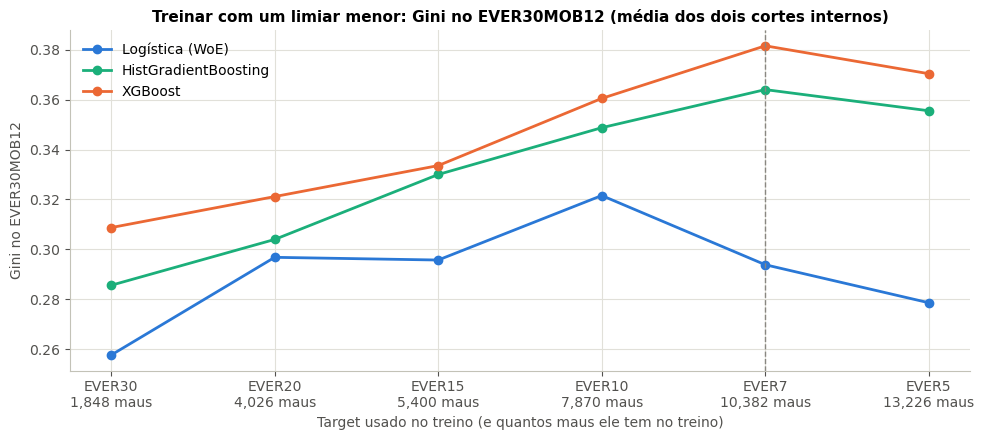

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rotulos = [t.replace("target_", "").replace("mob12", "").upper() for t in TARGETS_TREINO]
x = np.arange(len(TARGETS_TREINO))
for nome, cor in zip(FABRICAS, [AZUL, AQUA, LARANJA]):
    ax.plot(x, gini_interno[nome], "o-", color=cor, linewidth=2, markersize=6, label=nome)
ax.axvline(TARGETS_TREINO.index(TARGET_COMPARACAO), color=CINZA, linestyle="--", linewidth=1)
ax.set_xticks(x, [f"{r}\n{m:,} maus" for r, m in zip(rotulos, gini_interno["maus no treino"])])
ax.set_xlabel("Target usado no treino (e quantos maus ele tem no treino)")
ax.set_ylabel("Gini no EVER30MOB12")
ax.set_title("Treinar com um limiar menor: Gini no EVER30MOB12 (média dos dois cortes internos)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


- **Treinar com um limiar menor melhora a ordenação do próprio EVER30MOB12.** Na média dos três modelos, o Gini sobe de 0,284 (treino com EVER30) para 0,347 (treino com EVER7), um ganho de ~6 pontos. O EVER7 venceu o EVER30 nos três modelos e nos dois cortes.
- **O ganho vem do volume de eventos.** O treino tem 1.848 maus EVER30 e 10.382 maus EVER7, mais de 5x. Quem atrasa de 7 a 29 dias se parece com quem chega aos 30, e o modelo aprende esse perfil com muito mais exemplos.

### 4.1 Tuning: hiperparâmetros e limiar do target de treino

A comparação acima usou parâmetros fixos e seis limiares escolhidos à mão. Aqui o modelo escolhido passa por uma **busca bayesiana** (Optuna, com o amostrador TPE), e o **limiar de atraso do target de treino entra na busca como mais um hiperparâmetro**.


In [7]:
%%time
assert MODELO_FINAL == "XGBoost", "O tuning desta seção foi escrito para o XGBoost."
N_TENTATIVAS = 60

dias_partida = DIAS_COMPARACAO[TARGETS_TREINO.index(TARGET_COMPARACAO)]
partida = {"dias_atraso": dias_partida, **{k: v for k, v in PARAMS_XGBOOST.items() if k != "n_estimators"}}

tuning = TuningXGBoost(treino, FEATURES, CATEGORICAS, target_avaliacao=TARGET, cortes=CORTES_INTERNOS,
                       n_arvores=PARAMS_XGBOOST["n_estimators"]).executar(N_TENTATIVAS, partida)
tentativas = tuning.tentativas()

# O modelo final passa a usar o limiar e os hiperparâmetros da melhor tentativa
TARGET_TREINO = TuningXGBoost.coluna_target(tuning.melhor_dias_)
PARAMS_TUNING = tuning.melhores_parametros_
FABRICAS["XGBoost"] = lambda: ModeloXGBoost(CATEGORICAS, **PARAMS_TUNING)

print(f"Gini nos cortes internos: {tentativas.loc[0, 'Gini']:.4f} no ponto de partida e "
      f"{tentativas['Gini'].max():.4f} na melhor de {N_TENTATIVAS} tentativas (tentativa {tentativas.index[0]})")
print(f"Target de treino escolhido: {TARGET_TREINO}")
print("Hiperparâmetros escolhidos:", {k: round(v, 4) for k, v in PARAMS_TUNING.items()})
print("\nAs 10 melhores tentativas:")
display(tentativas.head(10).round(4))

Gini nos cortes internos: 0.3817 no ponto de partida e 0.3834 na melhor de 60 tentativas (tentativa 10)
Target de treino escolhido: target_ever7mob12
Hiperparâmetros escolhidos: {'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.0416, 'min_child_weight': 4.6125, 'reg_lambda': 4.3385, 'subsample': 0.7564, 'colsample_bytree': 0.9726}

As 10 melhores tentativas:


,Gini,colsample_bytree,dias_atraso,learning_rate,max_depth,min_child_weight,reg_lambda,subsample,Gini_cash
tentativa,,,,,,,,,
10,0.3834,0.9726,7,0.0416,3,4.6125,4.3385,0.7564,0.4640
0,0.3817,0.8000,7,0.0300,3,5.0000,5.0000,0.8000,0.4683
41,0.3806,0.8632,7,0.0276,2,3.5620,3.7279,0.7567,0.4750
36,0.3792,0.9654,7,0.0318,2,3.9941,6.7353,0.7284,0.4764
48,0.3791,0.9694,7,0.0328,2,4.9513,5.6806,0.7587,0.4749
37,0.3790,0.9872,7,0.0293,2,3.8863,4.8477,0.7361,0.4731
43,0.3786,0.8458,8,0.0285,2,5.8771,4.3462,0.7570,0.4721
51,0.3783,0.9232,7,0.0445,2,4.8272,5.2022,0.7078,0.4716
31,0.3777,0.9902,7,0.0244,2,7.5495,3.0962,0.7420,0.4729


CPU times: total: 43min 52s
Wall time: 5min 31s


## 5. Teste out-of-time

O teste (jul/2023 a fev/2024) não participou de nenhuma escolha. Os três modelos são treinados no **treino inteiro** (pedidos até jun/2023) com o target de treino escolhido no tuning (seção 4.1) e avaliados no **EVER30MOB12** do teste. O XGBoost usa os hiperparâmetros do tuning; os outros dois, os parâmetros fixos da seção 3.

- Além do target, medimos a ordenação do **EVER90MOB12** (default de Basileia) e o resultado só em **Cash loans**, o produto de 91% da submissão.
- As duas últimas linhas da tabela são conferências: o XGBoost treinado com o próprio EVER30MOB12, para ver no teste o efeito do target de treino, e o XGBoost com os parâmetros iniciais, para ver o efeito do tuning.
- O **intervalo de 95%** do Gini vem de bootstrap (reamostragem dos contratos do teste). Ele mostra quanto do número é ruído, porque o teste tem só ~100 maus.

Teste: 16,446 contratos, 99 maus EVER30, 15 maus EVER90, 39 maus em Cash loans


,AUC EVER30,Gini EVER30,IC95% inferior,IC95% superior,KS EVER30,Gini EVER90 (Basileia),Gini EVER30 só Cash loans
Logística (WoE),0.7039,0.4078,0.3097,0.4957,0.3171,0.5498,0.4661
HistGradientBoosting,0.7199,0.4397,0.3553,0.5239,0.3386,0.6226,0.4588
XGBoost,0.7309,0.4618,0.3761,0.5481,0.3754,0.5611,0.4527
XGBoost treinado com EVER30,0.6793,0.3586,0.2808,0.4485,0.3191,0.4640,0.4910
XGBoost sem tuning (ponto de partida),0.7338,0.4676,0.3789,0.5536,0.3722,0.5910,0.4777


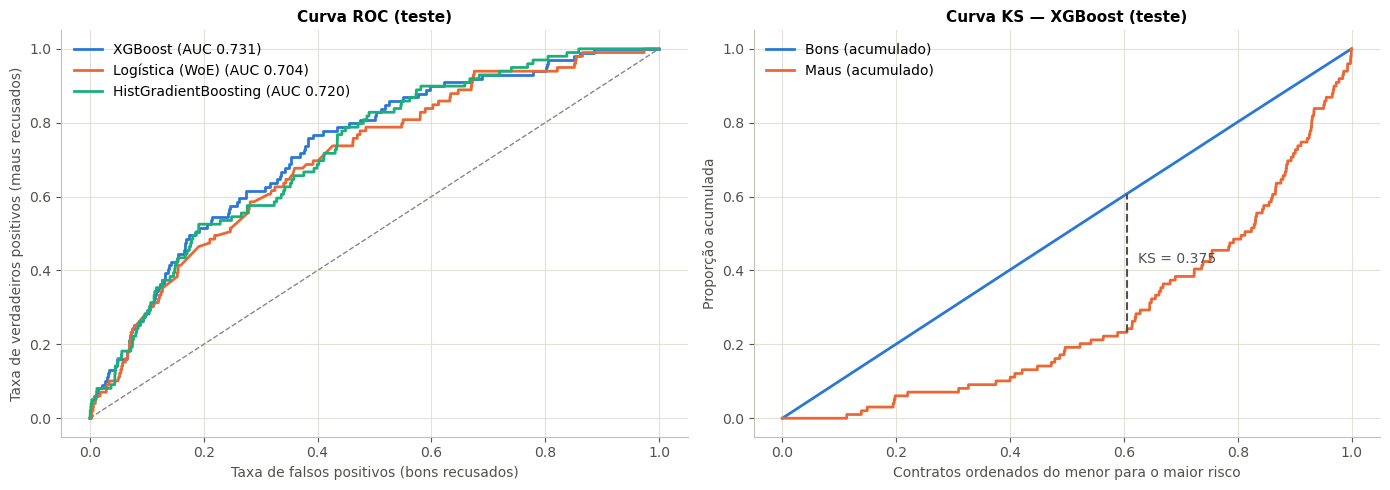

In [9]:
modelos = {nome: criar().fit(treino[FEATURES], treino[TARGET_TREINO]) for nome, criar in FABRICAS.items()}
previsao_teste = {nome: m.predict_proba(teste[FEATURES]) for nome, m in modelos.items()}

# Conferências: o modelo escolhido treinado com o próprio EVER30MOB12 e o XGBoost antes do tuning
referencia = f"{MODELO_FINAL} treinado com EVER30"
previsao_referencia = FABRICAS[MODELO_FINAL]().fit(treino[FEATURES], treino[TARGET]).predict_proba(teste[FEATURES])
sem_tuning = "XGBoost sem tuning (ponto de partida)"
previsao_sem_tuning = ModeloXGBoost(CATEGORICAS, **PARAMS_XGBOOST).fit(
    treino[FEATURES], treino[TARGET_COMPARACAO]).predict_proba(teste[FEATURES])

cash_teste = teste["tipo_contrato"].eq("Cash loans").to_numpy()
linhas = {}
for nome, p in {**previsao_teste, referencia: previsao_referencia, sem_tuning: previsao_sem_tuning}.items():
    metricas = avaliar(teste[TARGET], p)
    inferior, superior = ic_gini(teste[TARGET], p)
    linhas[nome] = {
        "AUC EVER30": metricas["AUC"], "Gini EVER30": metricas["Gini"], "IC95% inferior": inferior, "IC95% superior": superior,
        "KS EVER30": metricas["KS"],
        "Gini EVER90 (Basileia)": avaliar(teste[TARGET_BASILEIA], p)["Gini"],
        "Gini EVER30 só Cash loans": avaliar(teste.loc[cash_teste, TARGET], p[cash_teste])["Gini"],
    }
comparacao_teste = pd.DataFrame(linhas).T
print(f"Teste: {len(teste):,} contratos, {int(teste[TARGET].sum())} maus EVER30, {int(teste[TARGET_BASILEIA].sum())} maus EVER90, "
      f"{int(teste.loc[cash_teste, TARGET].sum())} maus em Cash loans")
display(comparacao_teste.round(4))

plot_roc_ks(teste[TARGET], {MODELO_FINAL: previsao_teste[MODELO_FINAL],
                            **{n: p for n, p in previsao_teste.items() if n != MODELO_FINAL}}, titulo="(teste)")

**Leitura.**

- **O teste confirma o XGBoost no target:**

| No teste | Logística | HistGradientBoosting | XGBoost |
|---|---|---|---|
| AUC no EVER30MOB12 | 0,704 | 0,720 | **0,731** |
| Gini no EVER30MOB12 (target) | 0,408 | 0,440 | **0,462** |
| KS no EVER30MOB12 | 0,317 | 0,339 | **0,375** |
| Gini no EVER90MOB12 (Basileia) | 0,55 | **0,62** | 0,56 |
| Gini só em Cash loans | **0,466** | 0,459 | 0,453 |

- **No target, a ordem dos modelos é a mesma dos cortes internos** (XGBoost, HistGradientBoosting, logística). A diferença entre os dois modelos de árvores é pequena: 2,2 pontos de Gini.
- **Os intervalos de confiança se sobrepõem.** Com 95% de confiança, o Gini do XGBoost fica entre 0,38 e 0,55, e o da logística, entre 0,31 e 0,50. Com 99 maus, o teste sozinho não permite cravar qual modelo é melhor. A escolha se apoia nos cortes internos da seção 4, que têm mais maus.
- **O target de treino se confirma no target principal:** o mesmo XGBoost treinado com EVER30 tem Gini de 0,359, contra 0,462 com EVER7 (+10,3 pontos).


## 6. Calibração

A ordenação está validada; falta o **nível**. O score cru do modelo não é a PD que queremos, por dois motivos:

1. O modelo foi treinado com o target de treino, de limiar menor, que acontece com muito mais frequência que o EVER30.
2. A taxa de maus caiu ao longo do histórico, então o treino tem inadimplência mais alta que as safras recentes.

A **calibração de Platt** resolve os dois de uma vez: uma regressão logística sobre o log-odds do score, ajustada contra o **EVER30MOB12 do teste**, a safra rotulada mais recente.

**Um nível por produto.** O calibrador tem uma inclinação única e um nível (intercepto) para cada tipo de contrato. O motivo é a submissão: ela só tem Cash loans e Revolving loans, mas 55% do teste são Consumer loans. Com um nível único, os Consumer loans puxam o nível dos Cash loans para baixo. A célula abaixo compara as duas versões de duas formas:

- **Maus observados contra esperados por produto**, com a calibração global.
- **Validação cruzada dentro do teste** (5 partes, 20 repetições). Um calibrador com mais parâmetros sempre parece melhor nos dados em que foi ajustado, então cada contrato é previsto por calibradores que não o viram. A medida é o log-loss; menor é melhor.

A calibração por produto não muda a ordem dos clientes dentro de cada produto. Entre produtos, pode mudar.

Como só há treino e teste, o calibrador é ajustado e conferido no mesmo teste. Ele tem quatro parâmetros (a inclinação e três níveis), então o risco de sobreajuste é pequeno. Ainda assim, o gráfico abaixo não é uma validação independente do nível.

,taxa real EVER30 (teste),taxa real do target de treino (teste),score médio sem calibrar,PD média calibrada,Brier sem calibrar,Brier calibrado
Logística (WoE),0.00602,0.06233,0.12081,0.00601,0.02185,0.00597
HistGradientBoosting,0.00602,0.06233,0.12189,0.00608,0.02244,0.00596
XGBoost,0.00602,0.06233,0.11960,0.00605,0.02237,0.00596


,contratos,maus observados,esperados (global),esperados (por produto),observado / esperado (global)
tipo_contrato,,,,,
Cash loans,6129,39,29.09,39.39,1.34
Consumer loans,9054,44,53.87,43.81,0.82
Revolving loans,1263,16,15.94,16.22,1.00


Log-loss x1000 em validação cruzada: global 34.74 | por produto 34.60 (por produto foi melhor em 20 de 20 repetições)
Gini da PD calibrada no teste: 0.484 por produto e 0.462 global (os níveis por produto foram ajustados neste mesmo teste)


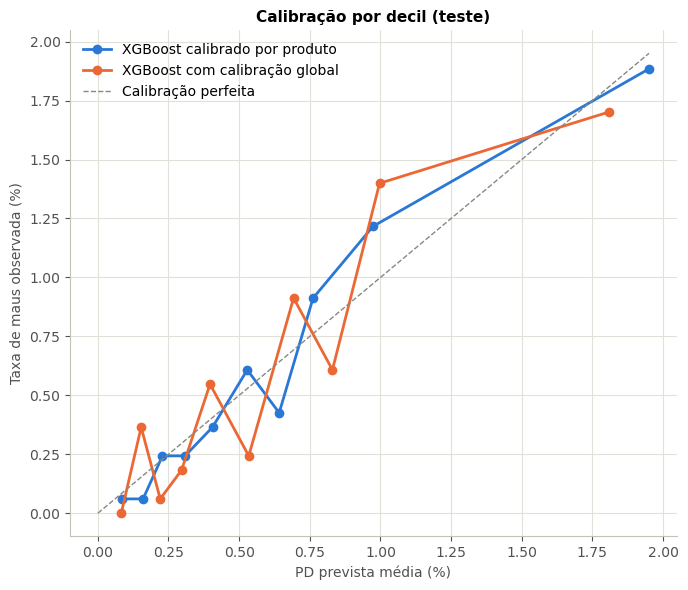

In [10]:
produto_teste = teste["tipo_contrato"]

# Calibração por produto: uma inclinação só e um nível para cada tipo de contrato. A global fica para comparação.
calibradores = {nome: CalibradorPlatt().fit(p, teste[TARGET], produto_teste) for nome, p in previsao_teste.items()}
previsao_teste_calibrada = {nome: calibradores[nome].transform(p, produto_teste) for nome, p in previsao_teste.items()}
modelo_final = ModeloCalibrado(modelos[MODELO_FINAL], calibradores[MODELO_FINAL], coluna_grupo="tipo_contrato")

score = previsao_teste[MODELO_FINAL]
pd_global = pd.Series(CalibradorPlatt().fit(score, teste[TARGET]).transform(score), index=teste.index)
pd_por_produto = pd.Series(previsao_teste_calibrada[MODELO_FINAL], index=teste.index)

nivel = pd.DataFrame({
    nome: {
        "taxa real EVER30 (teste)": teste[TARGET].mean(),
        "taxa real do target de treino (teste)": teste[TARGET_TREINO].mean(),
        "score médio sem calibrar": previsao_teste[nome].mean(),
        "PD média calibrada": previsao_teste_calibrada[nome].mean(),
        "Brier sem calibrar": avaliar(teste[TARGET], previsao_teste[nome])["Brier"],
        "Brier calibrado": avaliar(teste[TARGET], previsao_teste_calibrada[nome])["Brier"],
    }
    for nome in modelos
}).T
display(nivel.round(5))

# O nível único acerta cada produto? Maus observados contra os esperados pela calibração global do modelo final
por_produto = pd.DataFrame({
    "contratos": teste.groupby("tipo_contrato").size(),
    "maus observados": teste.groupby("tipo_contrato")[TARGET].sum().astype(int),
    "esperados (global)": pd_global.groupby(produto_teste).sum(),
    "esperados (por produto)": pd_por_produto.groupby(produto_teste).sum(),
})
por_produto["observado / esperado (global)"] = por_produto["maus observados"] / por_produto["esperados (global)"]
display(por_produto.round(2))

# Comparação em validação cruzada: cada contrato é previsto por calibradores que não o viram
cv = comparar_calibracao_cv(score, teste[TARGET], produto_teste)
print(f"Log-loss x1000 em validação cruzada: global {cv['global'].mean() * 1000:.2f} | por produto {cv['por grupo'].mean() * 1000:.2f} "
      f"(por produto foi melhor em {int((cv['por grupo'] < cv['global']).sum())} de {len(cv)} repetições)")
print(f"Gini da PD calibrada no teste: {avaliar(teste[TARGET], pd_por_produto)['Gini']:.3f} por produto e "
      f"{avaliar(teste[TARGET], pd_global)['Gini']:.3f} global (os níveis por produto foram ajustados neste mesmo teste)")

plot_calibracao(teste[TARGET], {f"{MODELO_FINAL} calibrado por produto": previsao_teste_calibrada[MODELO_FINAL],
                                 f"{MODELO_FINAL} com calibração global": pd_global.to_numpy()}, titulo="(teste)")

**Leitura.**

- **O score cru não é uma PD de EVER30.** Sem calibrar, o score médio do XGBoost no teste é de 12,0%, contra uma taxa real de EVER30 de 0,60%. Ele estima o EVER7, e no nível das safras antigas: a própria taxa de EVER7 no teste é de 6,2%.
- **Depois da calibração**, a PD média é de 0,60%, igual à taxa real, e o Brier cai de 0,022 para 0,006. A igualdade no total é esperada, porque o calibrador foi ajustado neste mesmo teste.
- **O nível único errava por produto.** Com a calibração global, os Cash loans tinham 39 maus contra 29 esperados (34% a mais), e os Consumer loans, 44 contra 54. Com um nível por produto, o esperado bate com o observado nos três, por construção.


## 7. Interpretação

### 7.1 Regressão logística: o scorecard

Cada feature entra pelo WoE da sua faixa. WoE alto significa uma faixa com proporcionalmente mais bons, então o **coeficiente esperado é negativo** (mais WoE, menos risco). Um coeficiente positivo indica uma feature cujo efeito se inverte quando as outras estão no modelo, quase sempre por correlação com outra feature.

,IV,coeficiente
hist_taxa_atraso,0.105,-0.267
hist_dpd_medio,0.100,-0.471
hist_taxa_atraso_365d,0.087,0.107
hist_dpd_max,0.074,-0.402
hist_dias_desde_ultimo_atraso,0.052,-0.948
hist_valor_aprovado_medio,0.045,-0.718
hist_n_aprovados,0.040,-0.409
hist_n_parcelas,0.039,-0.747
hist_n_contratos_com_parcela,0.038,-0.264
hist_n_pedidos,0.035,0.224


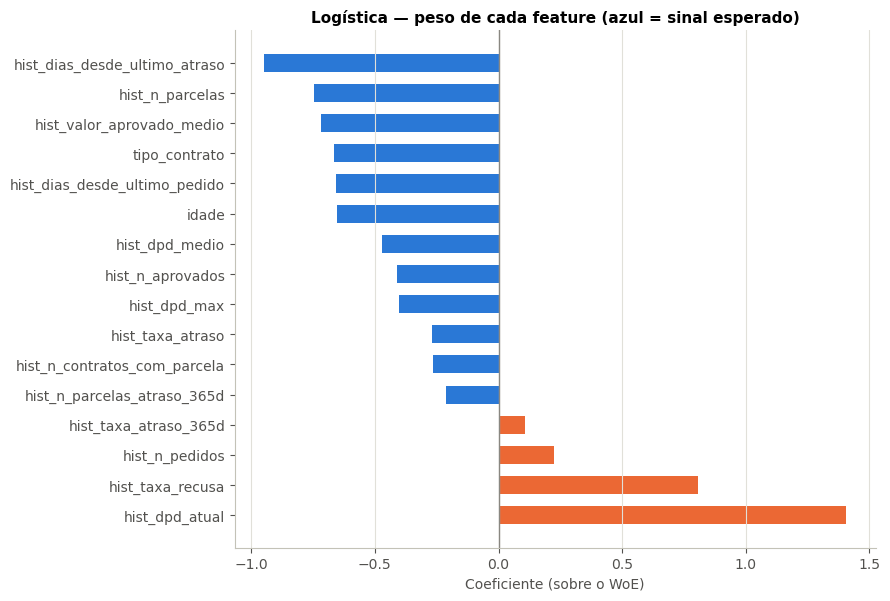

In [11]:
coeficientes = modelos["Logística (WoE)"].coeficientes()
display(coeficientes.round(3))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(coeficientes) + 1))
ordem = coeficientes.sort_values("coeficiente", ascending=False)
ax.barh(ordem.index, ordem["coeficiente"], color=[AZUL if c < 0 else LARANJA for c in ordem["coeficiente"]], height=0.6)
ax.axvline(0, color=CINZA, linewidth=1)
ax.set_xlabel("Coeficiente (sobre o WoE)")
ax.set_title("Logística — peso de cada feature (azul = sinal esperado)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 7.2 Modelo final: importância e curvas de resposta

Um modelo de árvores não tem coeficientes. Usamos duas ferramentas que servem para qualquer modelo (o código está em `modelagem.py`):

- **Importância por permutação:** embaralhamos os valores de uma feature e medimos quanto a previsão muda, em log-odds. Se quase não muda, o modelo não depende dela.
- **Dependência parcial:** damos a **todos** os contratos o mesmo valor de uma feature e calculamos a PD média. Repetindo para vários valores, a curva mostra como o modelo responde à feature com todo o resto igual.

As duas são calculadas numa amostra de 5.000 contratos do teste, com a PD já calibrada.

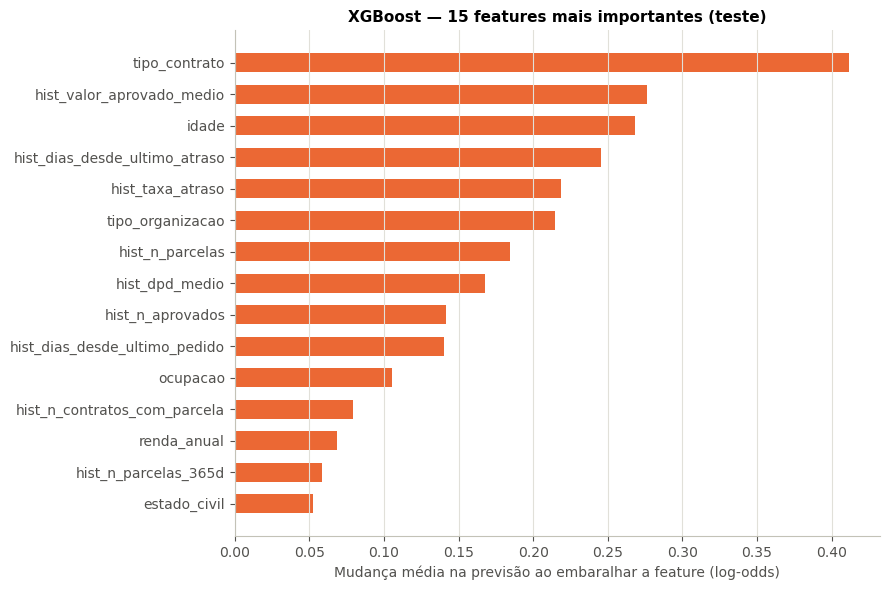

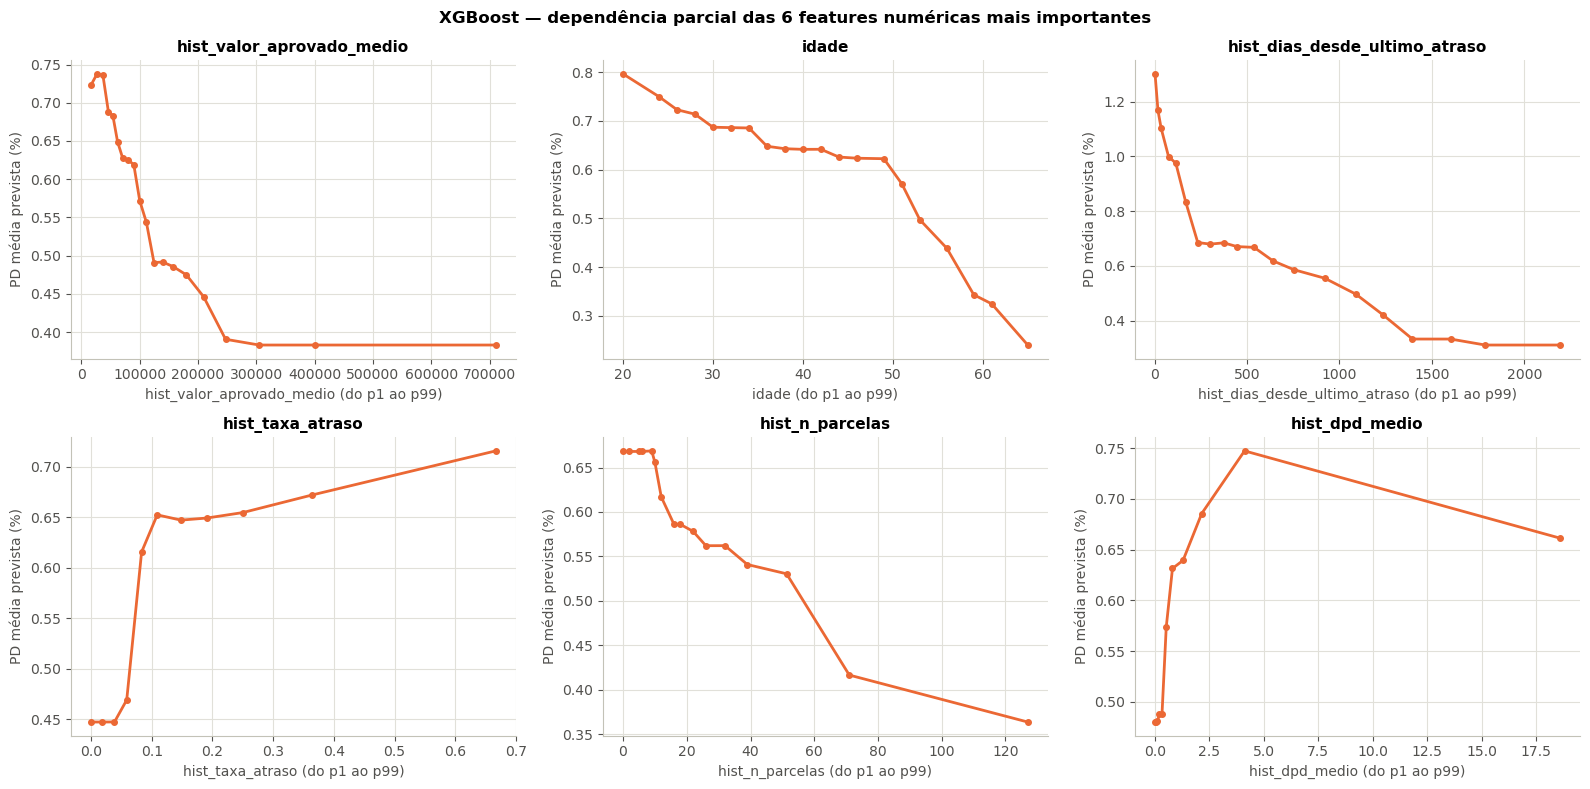

In [12]:
amostra = teste.sample(min(5000, len(teste)), random_state=SEED)[FEATURES]
importancia = importancia_permutacao(modelo_final, amostra)

fig, ax = plt.subplots(figsize=(9, 6))
top = importancia.head(15).sort_values()
ax.barh(top.index, top.values, color=LARANJA, height=0.6)
ax.set_xlabel("Mudança média na previsão ao embaralhar a feature (log-odds)")
ax.set_title(f"{MODELO_FINAL} — 15 features mais importantes (teste)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

numericas_top = [f for f in importancia.index if f not in CATEGORICAS and amostra[f].nunique() > 10][:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flat, numericas_top):
    curva = dependencia_parcial(modelo_final, amostra, feature) * 100
    ax.plot(curva.index, curva.values, "o-", color=LARANJA, linewidth=2, markersize=4)
    ax.set(xlabel=f"{feature} (do p1 ao p99)", ylabel="PD média prevista (%)", title=feature)
plt.suptitle(f"{MODELO_FINAL} — dependência parcial das 6 features numéricas mais importantes", fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura.**

- **O comportamento passado domina, como na EDA.** Das 15 features mais importantes, 9 são de histórico (`hist_*`): valor médio aprovado, dias desde o último atraso, taxa de parcelas em atraso, parcelas já pagas, atraso médio, aprovações anteriores, dias desde o último pedido, contratos com parcela e parcelas nos últimos 12 meses. Cinco vêm do cadastro (`idade`, `tipo_organizacao`, `ocupacao`, `renda_anual` e `estado_civil`).
- **O `tipo_contrato` aparece como a feature mais importante.** Ele entra duas vezes na PD final: como feature do modelo e como o grupo que define o nível da calibração (seção 6). As seguintes são o valor médio aprovado no passado e a idade.
- **Logística.** A maioria dos 16 coeficientes tem o sinal esperado (negativo). Quatro saem positivos: `hist_dpd_atual`, `hist_taxa_recusa`, `hist_n_pedidos` e `hist_taxa_atraso_365d`. São features muito correlacionadas com outras do modelo (por exemplo, `hist_dpd_atual` com `hist_dpd_max` e `hist_dpd_medio`), e o efeito delas "sobra" com o sinal trocado. Num scorecard de produção, elas sairiam (seleção *stepwise* ou por correlação) para que todo coeficiente tivesse leitura direta.
- **Curvas de resposta do XGBoost** (PD média prevista com todo o resto igual):
  - `hist_valor_aprovado_medio`: quem teve créditos pequenos no passado é mais arriscado (0,74% até ~37 mil). A PD cai até 0,38% acima de ~300 mil.
  - `idade`: a PD é de ~0,8% até os 24 anos, fica entre 0,69% e 0,62% dos 30 aos 49 e cai até 0,24% aos 65.
  - `hist_dias_desde_ultimo_atraso`: quem atrasou há poucos dias tem PD de ~1,3%. Ela cai para 0,68% depois de ~8 meses sem atraso e para ~0,32% depois de ~4 anos.
  - `hist_taxa_atraso`: a PD salta de 0,47% para 0,65% quando a parcela de pagamentos em atraso passa de ~6% para ~11%, e sobe pouco depois disso.
  - `hist_n_parcelas`: a PD é de 0,67% para quem pagou até 9 parcelas e cai devagar com a experiência, até 0,36% acima de ~130 parcelas.
  - `hist_dpd_medio`: a PD fica em ~0,48% até um atraso médio de 0,3 dia e sobe para ~0,63% a partir de 0,8 dia.
- **As curvas têm o sentido esperado:** atraso recente ou frequente aumenta o risco; idade, tempo sem atraso, créditos maiores no passado e mais parcelas pagas diminuem. O modelo mais complexo não está usando relações estranhas.
- **Cuidado na leitura:** a dependência parcial mostra o efeito médio de cada feature isolada. Ela não mostra interações, e alguns pontos combinam valores que não existem juntos na base (por exemplo, um histórico longo de parcelas pagas com 21 anos de idade).

## 8. Segmentos

Para cada grupo, comparamos a **PD média prevista** (calibrada) com a **taxa de maus observada** no teste.

contratos  maus  PD_prevista_%  taxa_real_%   Gini
segmento      grupo                                                              
sexo          F                    10882    62          0.592        0.570  0.467
              M                     5564    37          0.629        0.665  0.514
tipo_contrato Cash loans            6129    39          0.643        0.636  0.453
              Consumer loans        9054    44          0.484        0.486  0.499
              Revolving loans       1263    16          1.284        1.267    NaN
historico     Com histórico        12235    63          0.557        0.515  0.544
              Sem histórico         4211    36          0.742        0.855  0.242
faixa_idade   18–30                 3689    28          0.736        0.759  0.493
              31–45                 6446    38          0.638        0.590  0.557
              46–60                 5053    27          0.540        0.534  0.367
              60+                   1258     6          0.308        0.477    NaN

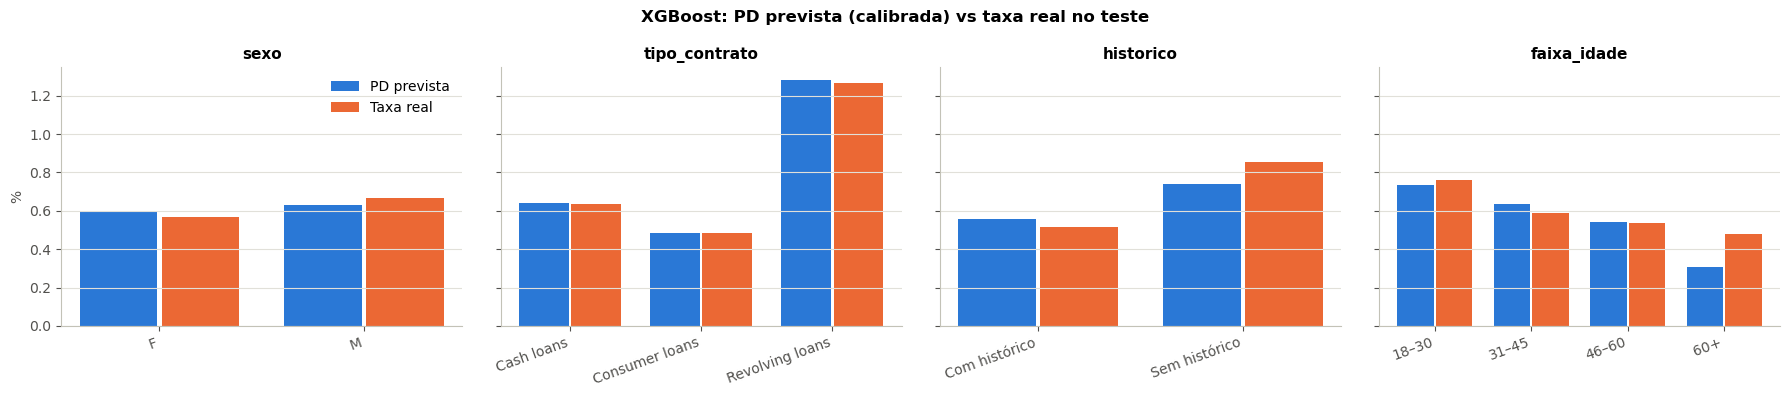

In [13]:
analise = teste.assign(pd_prevista=previsao_teste_calibrada[MODELO_FINAL])
analise["faixa_idade"] = pd.cut(analise["idade"], [17, 30, 45, 60, 100], labels=["18–30", "31–45", "46–60", "60+"])
analise["historico"] = np.where(analise["hist_sem_historico"].eq(1), "Sem histórico", "Com histórico")

linhas = []
for coluna in ["sexo", "tipo_contrato", "historico", "faixa_idade"]:
    for grupo, parte in analise.groupby(coluna, observed=True):
        linhas.append({
            "segmento": coluna, "grupo": grupo, "contratos": len(parte), "maus": int(parte[TARGET].sum()),
            "PD_prevista_%": parte["pd_prevista"].mean() * 100, "taxa_real_%": parte[TARGET].mean() * 100,
            "Gini": avaliar(parte[TARGET], parte["pd_prevista"])["Gini"] if parte[TARGET].sum() >= 20 else np.nan,
        })
segmentos = pd.DataFrame(linhas).set_index(["segmento", "grupo"])
display(segmentos.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (coluna, tabela) in zip(axes, segmentos.groupby(level=0, sort=False)):
    tabela = tabela.droplevel(0)
    x = np.arange(len(tabela))
    ax.bar(x - 0.2, tabela["PD_prevista_%"], width=0.38, color=AZUL, label="PD prevista")
    ax.bar(x + 0.2, tabela["taxa_real_%"], width=0.38, color=LARANJA, label="Taxa real")
    ax.set_xticks(x, tabela.index.astype(str), rotation=20, ha="right")
    ax.set_title(coluna)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("%")
axes[0].legend(frameon=False)
plt.suptitle(f"{MODELO_FINAL}: PD prevista (calibrada) vs taxa real no teste", fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura.**

- **Sexo: não há sinal de viés.** A PD prevista é de 0,59% para mulheres e 0,63% para homens, próximas das taxas reais (0,57% e 0,66%). O Gini é de 0,47 e 0,51.
- **Produto: previsto e real coincidem por construção** (seção 6): 0,64% em Cash loans, 0,48% contra 0,49% em Consumer loans e 1,28% contra 1,27% em Revolving loans. A ordenação dentro de cada produto é a do modelo: Gini de 0,45 em Cash loans e de 0,50 em Consumer loans.
- **Sem histórico: o grupo fica um pouco subestimado, e a ordenação é mais fraca.**
  - A PD prevista é de 0,74%, contra 0,85% real (36 maus contra 31 esperados). Quem tem histórico fica com 0,56% previsto contra 0,51% real.
  - É um efeito da calibração por produto: 85% dos contratos sem histórico do teste são Consumer loans, cujo nível caiu. A diferença cabe no ruído, e na submissão não há Consumer loans.
  - O Gini dentro do grupo é de 0,24, contra 0,54 de quem tem histórico. Para esses clientes o modelo tem praticamente só o cadastro e o tipo de contrato, então a PD deles tem mais incerteza, o que a política de crédito pode tratar com condições mais conservadoras.
  - Numa análise anterior, com outra versão do modelo, um modelo dedicado só a esses clientes não foi melhor. Por isso, mantemos um modelo único.
- **Idade:** a PD prevista e a taxa real caem juntas com a idade, sem desvio relevante até os 60 anos. Acima disso, o previsto fica abaixo do real (0,31% contra 0,48%), com só 6 maus.

## 9. Faixas de risco e submissão

**Faixas de risco.** A tabela de faixas (decis do score) é feita no teste. Ela é a base da política de crédito: para cada faixa, mostra a taxa de EVER30 (o target) e a de **EVER90** (Basileia), com que se mede a perda esperada.

,contratos,pd_media_%,taxa_ever30_%,taxa_ever90_%,maus_acumulados_%
faixa,,,,,
1,1645,0.09,0.06,0.00,100.00
2,1645,0.16,0.06,0.06,98.99
3,1644,0.23,0.24,0.00,97.98
4,1645,0.31,0.24,0.00,93.94
5,1644,0.41,0.36,0.00,89.90
6,1645,0.53,0.61,0.06,83.84
7,1644,0.64,0.43,0.06,73.74
8,1645,0.76,0.91,0.24,66.67
9,1644,0.97,1.22,0.12,51.52


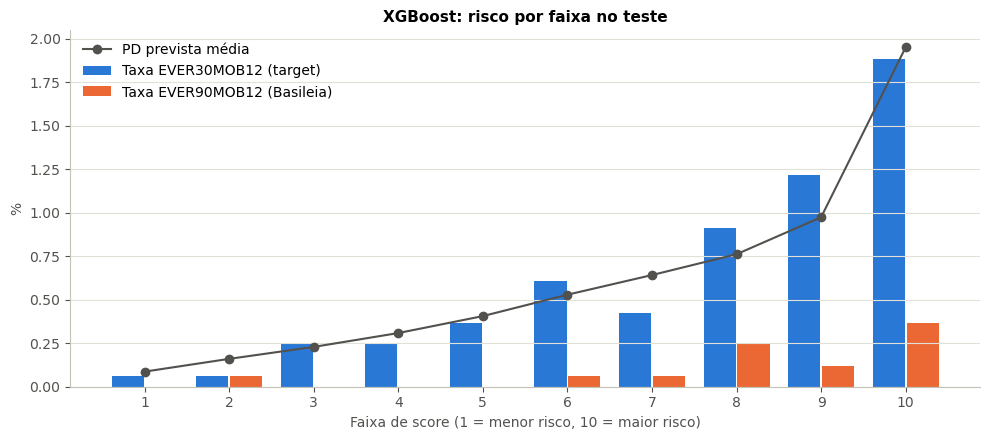

In [14]:
faixas = tabela_faixas(previsao_teste_calibrada[MODELO_FINAL], teste[TARGET], teste[TARGET_BASILEIA])
display((faixas * [1, 100, 100, 100, 100]).round(2).rename(columns={
    "pd_media": "pd_media_%", "taxa_maus": "taxa_ever30_%", "taxa_ever90": "taxa_ever90_%"}))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(1, len(faixas) + 1)
ax.bar(x - 0.2, faixas["taxa_maus"] * 100, width=0.38, color=AZUL, label="Taxa EVER30MOB12 (target)")
ax.bar(x + 0.2, faixas["taxa_ever90"] * 100, width=0.38, color=LARANJA, label="Taxa EVER90MOB12 (Basileia)")
ax.plot(x, faixas["pd_media"] * 100, "o-", color="#52514e", linewidth=1.5, label="PD prevista média")
ax.set_xticks(x)
ax.set(xlabel="Faixa de score (1 = menor risco, 10 = maior risco)", ylabel="%", title=f"{MODELO_FINAL}: risco por faixa no teste")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

- **A ordenação funciona:** a taxa EVER30 sobe de 0,06% nas duas primeiras faixas para 1,2% e 1,9% nas faixas 9 e 10. Só a faixa 7 quebra a sequência. Cada faixa tem ~1.650 contratos e poucos maus (de 1 a 31).


**Modelo final.** É o mesmo avaliado no teste: treinado com pedidos até jun/2023 e calibrado no teste (jul/2023 a fev/2024). Não há retreino, então as métricas da seção 5 valem para o modelo que gera a submissão.

submissao_case.csv salvo: 40,000 linhas


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
probabilidade_inadimplencia,40000.0,0.0062,0.0067,0.0002,0.0013,0.0022,0.0042,0.0079,0.0132,0.0299,0.2316


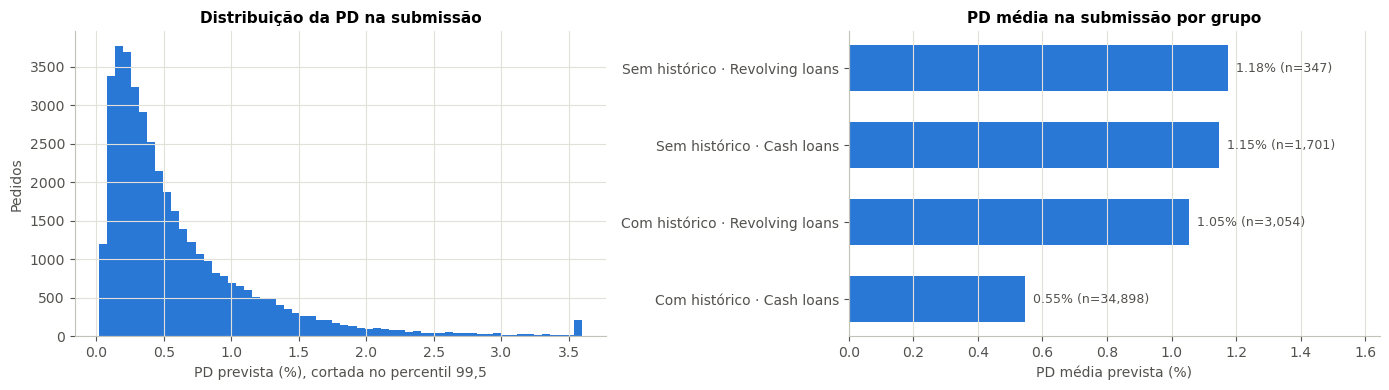

Configuração salva em outputs/modelo_final.json


In [15]:
pd_submissao = modelo_final.predict_proba(base_score[FEATURES])
submissao = pd.DataFrame({"id_cliente": base_score["id_cliente"], "probabilidade_inadimplencia": pd_submissao})
submissao.to_csv("submissao_case.csv", index=False)

assert len(submissao) == 40_000 and submissao["id_cliente"].is_unique and submissao["probabilidade_inadimplencia"].between(0, 1).all()
print(f"submissao_case.csv salvo: {len(submissao):,} linhas")
display(submissao["probabilidade_inadimplencia"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame().T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.clip(pd_submissao * 100, None, np.quantile(pd_submissao * 100, 0.995)), bins=60, color=AZUL)
axes[0].set(xlabel="PD prevista (%), cortada no percentil 99,5", ylabel="Pedidos", title="Distribuição da PD na submissão")
por_grupo = pd.DataFrame({
    "PD": pd_submissao * 100,
    "grupo": np.where(base_score["hist_sem_historico"].eq(1), "Sem histórico", "Com histórico") + " · " + base_score["tipo_contrato"],
}).groupby("grupo")["PD"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh(por_grupo.index, por_grupo["mean"], color=AZUL, height=0.6)
for y, (media, n) in enumerate(zip(por_grupo["mean"], por_grupo["size"])):
    axes[1].text(media, y, f"  {media:.2f}% (n={n:,})", va="center", fontsize=9, color="#52514e")
axes[1].set(xlabel="PD média prevista (%)", title="PD média na submissão por grupo")
axes[1].set_xlim(0, por_grupo["mean"].max() * 1.4)
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

configuracao = {
    "modelo": MODELO_FINAL,
    "target": TARGET,
    "target_treino": TARGET_TREINO,
    "hiperparametros": PARAMS_TUNING,
    "calibracao": "Platt com um nível por tipo de contrato",
    "tuning": {"tentativas": N_TENTATIVAS, "gini_interno_partida": round(float(tentativas.loc[0, "Gini"]), 4),
               "gini_interno_melhor": round(float(tentativas["Gini"].max()), 4)},
    "features": FEATURES,
    "categoricas": CATEGORICAS,
    "split": {"inicio_teste": str(split.inicio_teste.date())},
    "gini_cortes_internos": gini_interno.round(4).to_dict(orient="index"),
    "metricas_teste": comparacao_teste.round(4).to_dict(orient="index"),
}
(PASTA_SAIDA / "modelo_final.json").write_text(json.dumps(configuracao, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Configuração salva em outputs/modelo_final.json")

- A PD média na submissão é de **0,62%** (mediana de 0,42%, p99 de 2,99%). Fica perto da do teste (0,60%): a submissão tem mais clientes com histórico (95%, contra 74% no teste), o que reduz a PD, mas não tem Consumer loans, que são o produto de menor nível.
- **Revolving loans** recebem PD maior que Cash loans (1,1% contra 0,6%).
- **Clientes sem histórico recebem cerca do dobro da PD** em Cash loans: 1,15% contra 0,55%. Em Revolving loans a diferença é menor (1,18% contra 1,05%).
- A configuração do modelo (features, split, target de treino, hiperparâmetros, calibração e métricas) está em `outputs/modelo_final.json`.

## 9. Resumo e trabalhos futuros

**O que foi entregue:**

- **Modelo final: XGBoost**, treinado com pedidos até jun/2023 e calibrado na safra mais recente (jul/2023 a fev/2024), com um nível por tipo de contrato. Os hiperparâmetros vêm de um tuning bayesiano de 60 tentativas, avaliado só com dados do treino.
- **Target de treino: EVER7MOB12**, escolhido no mesmo tuning entre limiares de 5 a 30 dias. O modelo aprende com 10.382 maus em vez de 1.848. A PD entregue continua sendo a de **EVER30MOB12**.
- **42 features** de cadastro, de histórico e do pedido (tipo de contrato, dia e hora). As oito de tamanho e prazo do pedido ficaram de fora (seções 1 e 9.1).
- **Comparação com a logística (WoE) e o HistGradientBoosting.** O XGBoost foi o melhor nos cortes internos do treino e no target do teste.
- **Desempenho no teste fora do tempo** (jul/2023 a fev/2024):
  - AUC de 0,73 e Gini de 0,46 no target (EVER30MOB12), com intervalo de 95% do Gini de 0,38 a 0,55;
  - Gini de 0,56 no default de Basileia (EVER90MOB12), com só 15 casos;
  - Gini de 0,45 em Cash loans.
- `submissao_case.csv`, com a PD de 12 meses de cada um dos 40.000 pedidos.

**Principais decisões:**

1. **Split temporal em treino e teste**, nunca aleatório. Não há período de validação, para o treino incluir as safras até jun/2023.
2. **Modelo, target de treino e hiperparâmetros escolhidos com cortes dentro do treino.** O teste não participou de nenhuma escolha.
3. **Treino com limiar de 7 dias de atraso**, porque mais eventos ensinam o modelo a ordenar melhor o próprio EVER30 (no XGBoost, cerca de +7 pontos de Gini nos cortes internos e +10 no teste).
4. **Limiar tratado como hiperparâmetro do tuning** (seção 4.1), junto com os hiperparâmetros do XGBoost. A busca confirmou os 7 dias e a profundidade 3.
5. **Features de tamanho e prazo do pedido fora do modelo.** No treino elas descrevem um valor aprovado, e na submissão, um valor pedido. Com elas, o cliente sem histórico recebia a mesma PD dos demais (seção 9.1).
6. **Data de observação por cliente** (seção 5.2 da EDA). Um contrato só é rotulado se a janela de 12 meses terminou antes do pedido do cliente na submissão, que é até onde o histórico dele vai.
7. **Sem peso de classe**, para a PD sair como probabilidade de verdade. O nível é corrigido por **calibração** na safra mais recente.
8. **Calibração com um nível por produto** (seção 6). A submissão não tem Consumer loans, e com um nível único eles puxavam para baixo o nível dos Cash loans.
9. **`sexo` fora do modelo**, com a checagem de que a PD prevista acompanha a taxa real nos dois grupos.

**Limitações:**

- **O teste tem só 99 maus.** Os intervalos de confiança dos três modelos se sobrepõem, e a vantagem do XGBoost sobre o HistGradientBoosting é pequena. Em Cash loans os três modelos empatam, e no default de Basileia o HistGradientBoosting ficou à frente.
- **O tuning quase não mudou o modelo.** O ganho nos cortes internos foi de 0,2 ponto de Gini. No teste, os parâmetros iniciais ficaram um pouco acima (0,468 contra 0,462 no target, e 0,478 contra 0,453 em Cash loans), dentro do ruído.
- **O ganho do EVER7 não apareceu em Cash loans no teste** (0,453 contra 0,491 com EVER30, com 39 maus). Nos cortes internos, que têm mais maus, ele apareceu também nesse produto.
- **As features do pedido saíram por um argumento, não por uma medida na submissão.** A submissão não tem resultado conhecido, então não dá para verificar se elas ordenariam bem os pedidos atuais. No histórico, elas ajudam (seção 9.1).
- **Nível da PD.** Há duas incertezas, em sentidos opostos:
  - o nível dos Cash loans, que são 91% da submissão, vem de só 39 maus do teste. Com a calibração global ele seria cerca de 25% menor. A diferença entre produtos pode ser em parte ruído; se for, a PD dos Cash loans está alta, que é o erro conservador;
  - se a inadimplência continuar caindo, a PD de 2025 fica alta. É preciso recalibrar periodicamente.

- **O teste começa logo depois do fim do treino.** Em produção, haverá ~12 meses entre o último contrato com rótulo completo e os pedidos pontuados. Numa checagem fora deste notebook, treinar só até jun/2022 (12 meses de intervalo) deu Gini parecido no mesmo teste (0,47 contra 0,46), então o resultado não depende de o treino estar colado no teste. Além disso, 43% dos contratos do teste são de clientes que também têm um contrato nos últimos 12 meses do treino.
- **Clientes sem histórico são mais difíceis de ordenar** (Gini de 0,24 no teste, contra 0,51 de quem tem histórico), porque o modelo tem praticamente só o cadastro e o tipo de contrato deles.
- O treino só tem contratos aprovados de clientes que voltaram a pedir crédito (viés de seleção, discutido na EDA).

**Trabalhos futuros:**

- **Recalibrar com mais dados**, à medida que novas safras completarem 12 meses, para firmar o nível de cada produto.
- **Tuning mais amplo**, com mais tentativas e o número de árvores na busca. O ganho esperado é modesto, porque o limite está no sinal dos dados.
- **Modelo de sobrevivência**, para aproveitar os ~27 mil contratos sem 12 meses completos, a maioria aprovada depois de fev/2024. Eles ficam fora do treino, embora sejam os mais parecidos com a submissão. Em vez de perguntar "atrasou em 12 meses?", o modelo estima a chance de atraso a cada mês de vida do contrato (hazard em tempo discreto) ou o tempo até o atraso (por exemplo, XGBoost com o objetivo AFT). Um contrato com 5 meses de vida entra com os 5 meses observados, em vez de ser descartado. O mesmo modelo serviria para a PD de vida inteira (IFRS 9 / Res. CMN 4.966).
- **Mais informação para clientes sem histórico** (por exemplo, dados de birô).
- **Seleção de features na logística** (por correlação), para um scorecard com todos os sinais interpretáveis.
- **Monitoramento** de PSI e de calibração por safra.